# 01 · Collect and explore

**Goal:** build the dataset: the *Hundred Years' War* article (the **seed**), every article it links to (the **1-hop** articles), and the links between them.

Sections: **1. Data collection**, **2. Tables**, **3. Explore**.

All API calls live in `src/wiki.py`. Responses are cached in `data/raw/`, so re-running this notebook makes no network calls.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from tqdm import tqdm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import wiki

pd.set_option("display.max_colwidth", 70)
SEED = "Hundred Years' War"

## 1. Data collection

### The seed's links
`get_links` asks the Wikipedia API for every article a page links to (`generator=links`), with redirects resolved to the real title (*Black Prince* → *Edward the Black Prince*). It drops red links (pages that don't exist), links back to the page itself, and citation links that appear on almost every article, such as *ISBN (identifier)* and the *Wayback Machine*.

In [2]:
seed_links = wiki.get_links(SEED)
print(f"{len(seed_links)} articles linked from the seed")
pd.DataFrame.from_dict(seed_links, orient="index").head()

790 articles linked from the seed


,pageid,shortdesc,disambiguation
Artillery,2508,Long-ranged guns for land warfare,False
Assassination,2963,Willful killing of a prominent person,False
Baroque,3957,"Artistic style in Europe and colonies, c. 1600–1750",False
Bordeaux,4097,"Prefecture and commune in Nouvelle-Aquitaine, France",False
Black Death,4501,1346–1353 plague pandemic in Eurasia and North Africa,False


### Disambiguation pages
A **disambiguation page** ("X may refer to...") lists several topics that share a name. It isn't a topic itself, so it doesn't become a node.

In [3]:
disambig = [t for t, p in seed_links.items() if p["disambiguation"]]
print("Disambiguation pages:", disambig)

nodes = [SEED] + [t for t, p in seed_links.items() if not p["disambiguation"]]
print(f"{len(nodes)} nodes (the seed + {len(nodes) - 1} 1-hop articles)")

Disambiguation pages: ['Castilian Civil War', "Hundred Years' War (disambiguation)"]
789 nodes (the seed + 788 1-hop articles)


### Collect every article
For every node, get:

- its **links** (`get_links`),
- its **plain text** and short description (`get_article`), cut at the first *See also* or *References* heading,
- its **written links** (`get_written_links`): the links in the article's own source text. Links that `get_links` returns but that aren't written in the source were added by a **template** such as a navbox (the box of related links at the bottom of a page) or a sidebar.

The first run takes about an hour; after that, everything loads from the cache.

In [4]:
links_by_article, article_info, written_by_article, failed = {}, {}, {}, {}
for title in tqdm(nodes, desc="Collecting"):
    try:
        links_by_article[title] = wiki.get_links(title)
        article_info[title] = wiki.get_article(title)
        written_by_article[title] = set(wiki.get_written_links(title))
    except Exception as e:
        failed[title] = repr(e)
print(f"collected {len(article_info)} | failed {len(failed)}", failed or "")

Collecting:   0%|          | 0/789 [00:00<?, ?it/s]

Collecting:  16%|█▋        | 130/789 [00:00<00:00, 1296.50it/s]

Collecting:  39%|███▉      | 309/789 [00:00<00:00, 1585.60it/s]

Collecting:  62%|██████▏   | 488/789 [00:00<00:00, 1676.23it/s]

Collecting:  83%|████████▎ | 656/789 [00:00<00:00, 1444.93it/s]

Collecting: 100%|██████████| 789/789 [00:00<00:00, 1584.77it/s]

collected 789 | failed 0 


## 2. Tables

Two tables, stored as **Parquet** (a compressed, typed file format that loads much faster than CSV). CSV copies without the article text are saved next to them for viewing in Excel.

- **links**: one row per (source, target) pair:
  - `target_in_network`: whether the target is one of our 789 articles
  - `from_template`: whether the link was added by a template (navbox, sidebar) rather than written in the source article. Templates put the same block of links on every article they list, so these links say less about any one article. The column is kept as a signal for the clustering in Step 3.
- **articles**: one row per article:
  - `n_links_out`: all the articles it links to
  - `out_degree`: the network articles it links **to**; `pct_out_degree` = `out_degree / n_links_out`, the share of its links that stay in the network
  - `in_degree`: the network articles that link **to it**
  - `links_to_seed`: whether it links back to the seed
  - `first_paragraph` and `text`: the article's opening paragraph and full text

In [5]:
node_set = set(article_info)

links = pd.DataFrame(
    [(src, tgt) for src, targets in links_by_article.items() for tgt in targets],
    columns=["source", "target"],
)
links["target_in_network"] = links["target"].isin(node_set)
links["from_template"] = [tgt not in written_by_article[src] for src, tgt in zip(links["source"], links["target"])]
links.head()

,source,target,target_in_network,from_template
0,Hundred Years' War,Artillery,True,False
1,Hundred Years' War,Assassination,True,True
2,Hundred Years' War,Baroque,True,True
3,Hundred Years' War,Bordeaux,True,False
4,Hundred Years' War,Black Death,True,False


In [6]:
# Out-links per article, like SQL's GROUP BY source.
per_source = links.groupby("source").agg(
    n_links_out=("target", "size"),
    out_degree=("target_in_network", "sum"),
    links_to_seed=("target", lambda s: (s == SEED).any()),
)
per_source["pct_out_degree"] = per_source["out_degree"] / per_source["n_links_out"]

# In-links from network articles: the same links, grouped by target.
internal = links[links["target_in_network"]]
in_degree = internal.groupby("target").size().rename("in_degree")

articles = pd.DataFrame.from_dict(article_info, orient="index").reset_index(drop=True)
articles["is_seed"] = articles["title"] == SEED
articles["word_count"] = articles["text"].str.split().str.len()
articles["first_paragraph"] = articles["text"].str.strip().str.split("\n").str[0].str.strip()
articles = (
    articles.join(per_source, on="title").join(in_degree, on="title")
    .fillna({"n_links_out": 0, "out_degree": 0, "pct_out_degree": 0, "in_degree": 0, "links_to_seed": False})
    .astype({"n_links_out": int, "out_degree": int, "in_degree": int, "links_to_seed": bool})
)
articles = articles[["title", "pageid", "is_seed", "shortdesc", "first_paragraph", "word_count", "n_links_out",
                     "out_degree", "pct_out_degree", "in_degree", "links_to_seed", "text"]]
articles = articles.sort_values(["is_seed", "title"], ascending=[False, True], ignore_index=True)

out = ROOT / "data" / "processed"
articles.to_parquet(out / "articles.parquet", index=False)
links.to_parquet(out / "links.parquet", index=False)
articles.drop(columns="text").to_csv(out / "articles.csv", index=False, encoding="utf-8-sig")
links.to_csv(out / "links.csv", index=False, encoding="utf-8-sig")
print(f"articles: {len(articles)} rows | links: {len(links):,} rows ({links['target_in_network'].sum():,} within the network)")
articles.drop(columns=["text", "first_paragraph"]).head()

articles: 789 rows | links: 320,473 rows (48,006 within the network)


,title,pageid,is_seed,shortdesc,word_count,n_links_out,out_degree,pct_out_degree,in_degree,links_to_seed
0,Hundred Years' War,19038039,True,"Medieval Anglo-French conflicts, 1337–1453",9227,790,788,0.997468,520,False
1,1383–1385 Portuguese interregnum,368408,False,Period of history,1947,285,63,0.221053,100,True
2,1993 Cherbourg incident,34148711,False,Series of maritime incidents between the British Royal Navy and Fr...,703,36,5,0.138889,37,False
3,2021 Jersey dispute,67588790,False,Dispute over fishing licences,4686,544,53,0.097426,36,True
4,2022 Russian invasion of Ukraine,79400268,False,Campaign in ongoing war since 2014,6949,1496,4,0.002674,75,False


## 3. Explore

### Size and links
Article length and link counts vary by orders of magnitude, from stubs to long feature articles. These charts show the 1-hop articles; the seed is left out, since it links to every node.

In [7]:
hop = articles[~articles["is_seed"]]  # every node except the seed
metrics = ["word_count", "n_links_out", "out_degree", "pct_out_degree", "in_degree"]
hop[metrics].describe().round(2)

,word_count,n_links_out,out_degree,pct_out_degree,in_degree
count,788.00,788.00,788.00,788.00,788.00
mean,3538.20,405.69,59.92,0.29,60.26
std,4059.34,456.46,50.07,0.26,47.86
min,33.00,4.00,0.00,0.00,1.00
25%,744.75,91.00,15.00,0.07,21.00
50%,1967.00,206.00,54.00,0.19,51.00
75%,4733.75,584.00,97.00,0.45,89.25
max,32652.00,2689.00,233.00,0.96,371.00


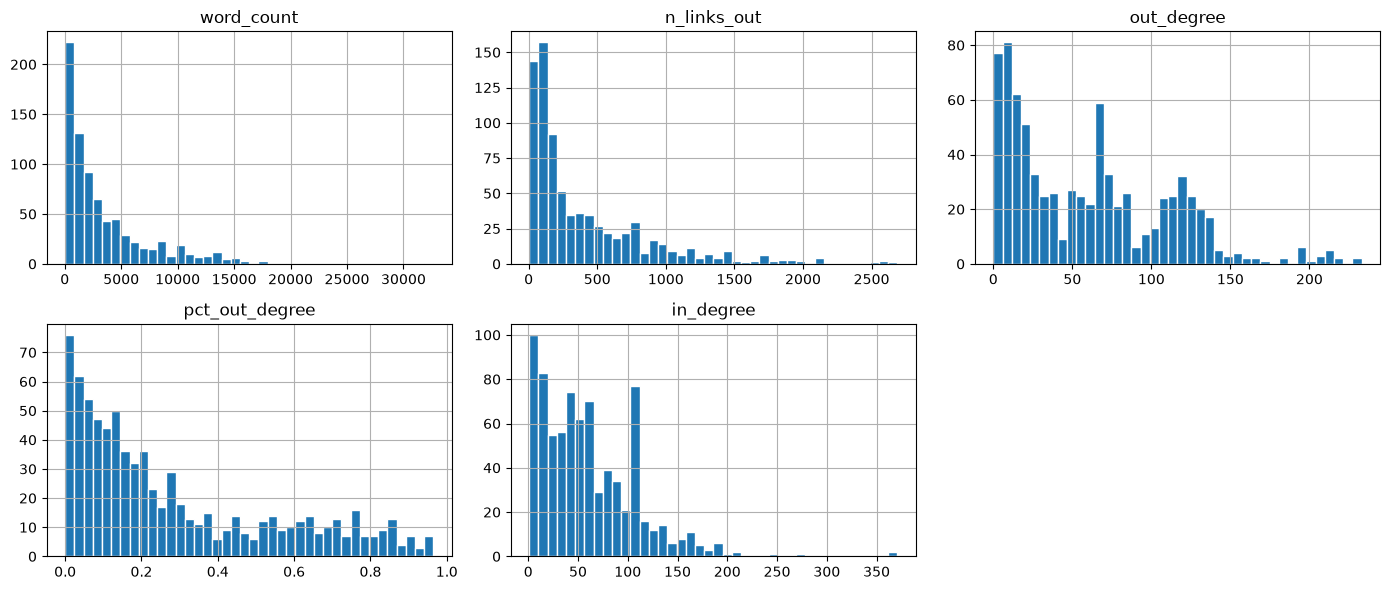

In [8]:
axes = hop[metrics].hist(bins=40, layout=(2, 3), figsize=(14, 6), edgecolor="white")
axes[1, 2].axis("off")
plt.tight_layout()

### Out-degree and in-degree
- **Out-degree** counts the network articles an article links to; **`pct_out_degree`** is the share of all its links that stay in the network, a sign of how focused it is on this topic.
- **In-degree** counts the network articles that link to it: how central it is in the network.

The top 5 by each:

In [9]:
cols = ["title", "shortdesc", "out_degree", "pct_out_degree", "in_degree"]
print("Top 5 by out-degree:")
display(hop.nlargest(5, "out_degree")[cols].round(2))
print("Top 5 by share of links in the network:")
display(hop.nlargest(5, "pct_out_degree")[cols].round(2))
print("Top 5 by in-degree:")
hop.nlargest(5, "in_degree")[cols].round(2)

Top 5 by out-degree:


,title,shortdesc,out_degree,pct_out_degree,in_degree
525,Middle Ages,European history from the 5th to 15th centuries,233,0.19,274
459,Late Middle Ages,Period of European history between AD 1300 and 1500,230,0.27,188
354,"Hundred Years' War, 1337–1360",First phase of the Hundred Years' War,221,0.60,157
193,Crusades,Religious wars of the High Middle Ages,218,0.13,201
326,High Middle Ages,Period of European history between AD 1000 and 1350,214,0.25,176


Top 5 by share of links in the network:


,title,shortdesc,out_degree,pct_out_degree,in_degree
749,Truce of Espléchin,1340 truce during Hundred Years' War,55,0.96,53
50,Battle of Beaugency (1429),Battle of the Hundred Years' War,115,0.95,104
695,Siege of Saint-Pierre-le-Moûtier,1429 battle of the Armagnac–Burgundian Civil War,107,0.95,100
738,Tournaisis campaign of 1340,Military campaign of 1340 during the Hundred Years' War,69,0.95,50
71,Battle of Jargeau,1429 battle of the Hundred Years' War,137,0.94,135


Top 5 by in-degree:


,title,shortdesc,out_degree,pct_out_degree,in_degree
444,Kingdom of England,Sovereign state in Europe before 1707,160,0.16,371
445,Kingdom of France,Country in Western Europe (843–1792; 1814–1830),181,0.29,365
525,Middle Ages,European history from the 5th to 15th centuries,233,0.19,274
342,Holy Roman Empire,European political entity (800/962–1806),213,0.16,250
230,Edward III,King of England from 1327 to 1377,126,0.23,212


Broad articles (*Middle Ages*, *Kingdom of England*) have the most links in both directions; short articles about the war's battles and campaigns have the highest share of links in the network.

### Do the 1-hop articles link back?
An article that links back to *Hundred Years' War* probably treats the war as relevant to its own topic.

In [10]:
print(f"{hop['links_to_seed'].mean():.0%} of 1-hop articles link back to the seed")
hop.groupby("links_to_seed").agg(
    n_articles=("title", "size"),
    word_count=("word_count", "median"),
    out_degree=("out_degree", "median"),
    in_degree=("in_degree", "median"),
)

66% of 1-hop articles link back to the seed


,n_articles,word_count,out_degree,in_degree
links_to_seed,,,,
False,268,1185.5,11.0,22.0
True,520,2394.5,75.0,62.0


### Links from templates
How many links come from templates rather than the articles' own text.

In [11]:
pd.DataFrame({
    "links": [len(links), len(internal), (links["source"] == SEED).sum()],
    "from_template": [links["from_template"].mean(), internal["from_template"].mean(),
                      links.loc[links["source"] == SEED, "from_template"].mean()],
}, index=["all links", "links between network articles", "the seed's links"]).round(2)

,links,from_template
all links,320473,0.58
links between network articles,48006,0.69
the seed's links,790,0.57


Templates add a large share of the links, especially between network articles: a navbox lists a group of related articles and appears on each of their pages, so they all link to each other. That inflates link-based similarity for articles that share a navbox, which is why `from_template` is kept as a column for the clustering.

### The 2-hop layer
Titles outside the network that many 1-hop articles link to: what the neighborhood talks about.

In [12]:
external = links[~links["target_in_network"]]
print(f"{external['target'].nunique():,} unique 2-hop titles")
external.groupby("target")["source"].nunique().nlargest(10).rename("linked from # network articles").to_frame()

109,955 unique 2-hop titles


,linked from # network articles
target,
Geographic coordinate system,169
Catholic Church,162
Latin,151
Paris,135
Charlemagne,103
England,91
Louis XIV,88
House of Habsburg,85
Napoleon,85


### The graph
A **directed graph**: nodes = articles, an edge A → B when A links to B.

- **Density:** the share of all possible edges that exist.
- **Reciprocity:** the share of edges whose reverse also exists (A → B and B → A).
- **Weakly connected components:** groups of nodes connected when edge direction is ignored.

In [13]:
G = nx.DiGraph()
G.add_nodes_from(articles["title"])
G.add_edges_from(internal[["source", "target"]].itertuples(index=False))
components = list(nx.weakly_connected_components(G))
print(f"nodes {G.number_of_nodes()} | edges {G.number_of_edges():,} | density {nx.density(G):.3f} | reciprocity {nx.reciprocity(G):.2f}")
print(f"weakly connected components: {len(components)} (largest has {max(map(len, components))} nodes)")

nodes 789 | edges 48,006 | density 0.077 | reciprocity 0.70
weakly connected components: 1 (largest has 789 nodes)


### Sanity checks

In [14]:
assert articles["title"].is_unique, "duplicate article titles"
assert not links.duplicated(["source", "target"]).any(), "duplicate links"
assert not (links["source"] == links["target"]).any(), "self-links"
assert not articles["title"].str.contains("(identifier)", regex=False).any(), "citation identifiers"
assert articles["in_degree"].sum() == articles["out_degree"].sum() == len(internal), "every internal link counts once in each direction"
print("No duplicate titles or links, no self-links or citation identifiers; degrees add up.")

No duplicate titles or links, no self-links or citation identifiers; degrees add up.
